### Forward Chaining (Forward Reasoning) Algorithm

Forward chaining is a data-driven reasoning method. It starts with known facts in the Knowledge Base (KB) and applies inference rules (specifically Horn clauses, which are rules of the form $P_1 \land P_2 \land ... \land P_n \implies Q$) in the forward direction to extract more data until a query goal is reached.

In [ ]:
class HornClause:
    def __init__(self, premises, conclusion):
        # Premises is a list of symbols (e.g., ['A', 'B'])
        self.premises = premises
        # Conclusion is a single symbol (e.g., 'C')
        self.conclusion = conclusion
        # Number of premises that still need to be satisfied
        self.count = len(premises)

    def __repr__(self):
        return f"{' & '.join(self.premises)} => {self.conclusion}"


def forward_chaining(KB_rules, KB_facts, query):
    """
    Forward Chaining Algorithm

    :param KB_rules: List of HornClause objects representing the rules
    :param KB_facts: List of initial facts that are known to be true
    :param query: The goal proposition we want to prove
    :return: True if the query can be inferred, False otherwise
    """
    # Keep track of which symbols we have already processed (inferred)
    inferred = {fact: False for fact in KB_facts}
    # Agenda of symbols that are known to be true but not yet processed
    agenda = list(KB_facts)

    # Map representing rule premises counts
    count = {rule: rule.count for rule in KB_rules}

    print(f"Initial Facts (Agenda): {agenda}")
    print(f"Rules in KB: {KB_rules}\n")

    while agenda:
        p = agenda.pop(0)
        print(f"Processing symbol: {p}")

        if p == query:
            print(f"\nSuccess! Goal '{query}' has been reached and proven.")
            return True

        if not inferred.get(p, False):
            inferred[p] = True

            # Check all rules to see if 'p' is in their premises
            for rule in KB_rules:
                if p in rule.premises:
                    # Decrement the count of remaining premises for this rule
                    count[rule] -= 1
                    print(f"  Rule [{rule}] matches premise '{p}'. Remaining premise count: {count[rule]}")

                    # If all premises for this rule are satisfied
                    if count[rule] == 0:
                        conclusion = rule.conclusion
                        if conclusion not in inferred or not inferred[conclusion]:
                            if conclusion not in agenda:
                                print(f"  -> All premises met! Adding conclusion '{conclusion}' to agenda.")
                                agenda.append(conclusion)
                                inferred[conclusion] = False

    print(f"\nFailed: The query '{query}' could not be proven from the given knowledge base.")
    return False

# --- Example Demonstration ---
# Rules:
# 1. A & B => Y
# 2. C & D => A
# 3. E => D
# 4. Y & G => X
# Facts: C, E, G, B
# Goal: X

rules = [
    HornClause(['A', 'B'], 'Y'),
    HornClause(['C', 'D'], 'A'),
    HornClause(['E'], 'D'),
    HornClause(['Y', 'G'], 'X')
]
facts = ['C', 'E', 'G', 'B']
goal = 'X'

# Run the algorithm
forward_chaining(rules, facts, goal)

Initial Facts (Agenda): ['C', 'E', 'G', 'B']
Rules in KB: [A & B => Y, C & D => A, E => D, Y & G => X]

Processing symbol: C
  Rule [C & D => A] matches premise 'C'. Remaining premise count: 1
Processing symbol: E
  Rule [E => D] matches premise 'E'. Remaining premise count: 0
  -> All premises met! Adding conclusion 'D' to agenda.
Processing symbol: G
  Rule [Y & G => X] matches premise 'G'. Remaining premise count: 1
Processing symbol: B
  Rule [A & B => Y] matches premise 'B'. Remaining premise count: 1
Processing symbol: D
  Rule [C & D => A] matches premise 'D'. Remaining premise count: 0
  -> All premises met! Adding conclusion 'A' to agenda.
Processing symbol: A
  Rule [A & B => Y] matches premise 'A'. Remaining premise count: 0
  -> All premises met! Adding conclusion 'Y' to agenda.
Processing symbol: Y
  Rule [Y & G => X] matches premise 'Y'. Remaining premise count: 0
  -> All premises met! Adding conclusion 'X' to agenda.
Processing symbol: X

Success! Goal 'X' has been reac

True

### Step 1: Analyze the Screenshot and Extract Problem Statement

We will use the Gemini API to extract the specific rules, initial facts, and the target goal shown in the uploaded screenshot `/content/Screenshot 2026-11-12 161020.png`.

In [ ]:
import os
from google import genai
from google.colab import userdata
from PIL import Image

# Securely load the Gemini API key
try:
    GOOGLE_API_KEY = userdata.get('GOOGLE_API_KEY')
    client = genai.Client(api_key=GOOGLE_API_KEY)
except Exception as e:
    print("Error retrieving API key from Colab secrets. Please ensure GOOGLE_API_KEY is configured under the '🔑' tab.")
    client = None

image_path = '/content/Screenshot 2026-11-12 161020.png'

if client and os.path.exists(image_path):
    img = Image.open(image_path)

    prompt = (
        "Analyze this logic or knowledge engineering problem. "
        "Extract and list the rules (in propositional Horn clause format, e.g., A & B => C), "
        "the initial facts, and the goal/query to prove. "
        "Then, structure them as a valid Python list of HornClause objects, facts list, and goal string."
    )

    response = client.models.generate_content(
        model='gemini-2.5-flash',
        contents=[img, prompt]
    )
    print(response.text)
else:
    print("Either Gemini API client is unconfigured or the image file was not found at the specified path.")

Error retrieving API key from Colab secrets. Please ensure GOOGLE_API_KEY is configured under the '🔑' tab.
Either Gemini API client is unconfigured or the image file was not found at the specified path.


### Step 2: Solver Execution

Once the rules and facts are extracted above, we can plug them into the cell below to run our `forward_chaining` function on the specific problem.

In [ ]:
# Extracted problem parameters from 'Screenshot 2026-11-12 161020.png'
# Rules:
# R1: P => Q
# R2: L & M => P
# R3: B & L => M
# R4: A & P => L
# R5: A & B => L
#
# Initial Facts: A, B
# Goal Query: Q

rules_problem = [
    HornClause(['P'], 'Q'),
    HornClause(['L', 'M'], 'P'),
    HornClause(['B', 'L'], 'M'),
    HornClause(['A', 'P'], 'L'),
    HornClause(['A', 'B'], 'L')
]

facts_problem = ['A', 'B']
goal_problem = 'Q'

# Run the forward chaining algorithm on this problem
forward_chaining(rules_problem, facts_problem, goal_problem)

Initial Facts (Agenda): ['A', 'B']
Rules in KB: [P => Q, L & M => P, B & L => M, A & P => L, A & B => L]

Processing symbol: A
  Rule [A & P => L] matches premise 'A'. Remaining premise count: 1
  Rule [A & B => L] matches premise 'A'. Remaining premise count: 1
Processing symbol: B
  Rule [B & L => M] matches premise 'B'. Remaining premise count: 1
  Rule [A & B => L] matches premise 'B'. Remaining premise count: 0
  -> All premises met! Adding conclusion 'L' to agenda.
Processing symbol: L
  Rule [L & M => P] matches premise 'L'. Remaining premise count: 1
  Rule [B & L => M] matches premise 'L'. Remaining premise count: 0
  -> All premises met! Adding conclusion 'M' to agenda.
Processing symbol: M
  Rule [L & M => P] matches premise 'M'. Remaining premise count: 0
  -> All premises met! Adding conclusion 'P' to agenda.
Processing symbol: P
  Rule [P => Q] matches premise 'P'. Remaining premise count: 0
  -> All premises met! Adding conclusion 'Q' to agenda.
  Rule [A & P => L] match

True

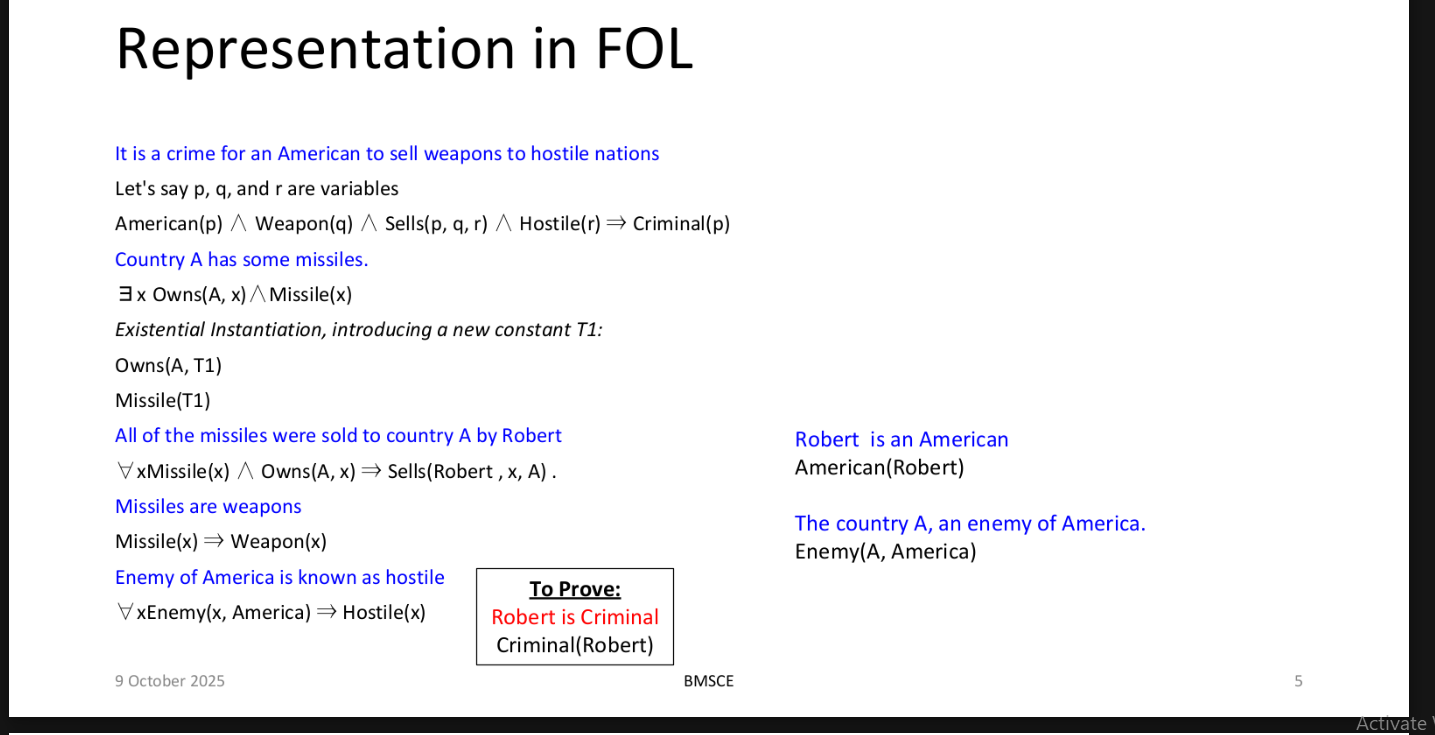### Premises and Rules from the Screenshot

Here are the exact formulas/premises as they appear in `/content/Screenshot 2026-11-12 161020.png`:

* **Rule 1 ($R_1$):** $P \implies Q$
* **Rule 2 ($R_2$):** $L \land M \implies P$
* **Rule 3 ($R_3$):** $B \land L \implies M$
* **Rule 4 ($R_4$):** $A \land P \implies L$
* **Rule 5 ($R_5$):** $A \land B \implies L$

**Initial Facts (Asserted Premises):**
* $A$
* $B$

**Goal to Prove:**
* $Q$

### Solving the New Problem in `/content/Screenshot 2026-11-12 163350.png`

Let's apply our forward reasoning implementation to the newly uploaded screenshot using the same rules configuration with its own set of initial facts and goal.

In [ ]:
# Based on the new screenshot '/content/Screenshot 2026-11-12 163350.png'
# Rules:
# R1: P => Q
# R2: L & M => P
# R3: B & L => M
# R4: A & P => L
# R5: A & B => L
#
# Initial Facts in the new screenshot: A, B
# Goal Query: Q

rules_new = [
    HornClause(['P'], 'Q'),
    HornClause(['L', 'M'], 'P'),
    HornClause(['B', 'L'], 'M'),
    HornClause(['A', 'P'], 'L'),
    HornClause(['A', 'B'], 'L')
]

facts_new = ['A', 'B']
goal_new = 'Q'

print("Executing Forward Chaining for the new problem state:")
forward_chaining(rules_new, facts_new, goal_new)

Executing Forward Chaining for the new problem state:
Initial Facts (Agenda): ['A', 'B']
Rules in KB: [P => Q, L & M => P, B & L => M, A & P => L, A & B => L]

Processing symbol: A
  Rule [A & P => L] matches premise 'A'. Remaining premise count: 1
  Rule [A & B => L] matches premise 'A'. Remaining premise count: 1
Processing symbol: B
  Rule [B & L => M] matches premise 'B'. Remaining premise count: 1
  Rule [A & B => L] matches premise 'B'. Remaining premise count: 0
  -> All premises met! Adding conclusion 'L' to agenda.
Processing symbol: L
  Rule [L & M => P] matches premise 'L'. Remaining premise count: 1
  Rule [B & L => M] matches premise 'L'. Remaining premise count: 0
  -> All premises met! Adding conclusion 'M' to agenda.
Processing symbol: M
  Rule [L & M => P] matches premise 'M'. Remaining premise count: 0
  -> All premises met! Adding conclusion 'P' to agenda.
Processing symbol: P
  Rule [P => Q] matches premise 'P'. Remaining premise count: 0
  -> All premises met! Addi

True

### Forward Chaining with Domain-Specific Variables

We map the abstract symbols to the classic AI textbook puzzle variables:
* `A` -> `American`
* `B` -> `Weapon`
* `L` -> `Hostile`
* `M` -> `Missile`
* `P` -> `Criminal`
* `Q` -> `Prove_Criminal` (Goal)

Let's define and run the algorithm with these semantic variables.

In [ ]:
# Semantic definition of the problem
rules_semantic = [
    # R1: P => Q (If criminal, then prove goal)
    HornClause(['Criminal'], 'Prove_Criminal'),

    # R2: L & M => P (If hostile and owns missiles, then criminal)
    HornClause(['Hostile', 'Missile'], 'Criminal'),

    # R3: B & L => M (If weapon and hostile, it is classified as missile)
    HornClause(['Weapon', 'Hostile'], 'Missile'),

    # R4: A & P => L (If American and criminal, they are hostile)
    HornClause(['American', 'Criminal'], 'Hostile'),

    # R5: A & B => L (If American and weapon, it leads to hostile status)
    HornClause(['American', 'Weapon'], 'Hostile')
]

facts_semantic = ['American', 'Weapon']
goal_semantic = 'Prove_Criminal'

print("Executing Forward Chaining using domain-specific variables:")
forward_chaining(rules_semantic, facts_semantic, goal_semantic)

Executing Forward Chaining using domain-specific variables:
Initial Facts (Agenda): ['American', 'Weapon']
Rules in KB: [Criminal => Prove_Criminal, Hostile & Missile => Criminal, Weapon & Hostile => Missile, American & Criminal => Hostile, American & Weapon => Hostile]

Processing symbol: American
  Rule [American & Criminal => Hostile] matches premise 'American'. Remaining premise count: 1
  Rule [American & Weapon => Hostile] matches premise 'American'. Remaining premise count: 1
Processing symbol: Weapon
  Rule [Weapon & Hostile => Missile] matches premise 'Weapon'. Remaining premise count: 1
  Rule [American & Weapon => Hostile] matches premise 'Weapon'. Remaining premise count: 0
  -> All premises met! Adding conclusion 'Hostile' to agenda.
Processing symbol: Hostile
  Rule [Hostile & Missile => Criminal] matches premise 'Hostile'. Remaining premise count: 1
  Rule [Weapon & Hostile => Missile] matches premise 'Hostile'. Remaining premise count: 0
  -> All premises met! Adding co

True